In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# **Question 1**

In [3]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_laplace, maximum_filter


In [4]:
im = cv.imread(
    "/kaggle/input/datasets/isithadinujaya/images-a-2/a2images/a2images/the_berry_farms_sunflower_field.jpeg",
    cv.IMREAD_REDUCED_COLOR_4
)

gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0

In [5]:
sigma_min = 1.5
sigma_max = 25.0
number_of_scales = 30
threshold_relative = 0.12

sigmas = np.geomspace(sigma_min, sigma_max, number_of_scales)

# Extra scales allow extrema testing at both ends of the search range.
scale_ratio = sigmas[1] / sigmas[0]
evaluation_sigmas = np.concatenate((
    [sigmas[0] / scale_ratio],
    sigmas,
    [sigmas[-1] * scale_ratio]
))


In [6]:
responses = np.stack([
    np.abs(
        sigma**2 * gaussian_laplace(
            gray, sigma=sigma, mode="reflect"
        )
    )
    for sigma in evaluation_sigmas
], axis=0)


In [7]:
local_maximum = maximum_filter(
    responses,
    size=(3, 3, 3),
    mode="constant",
    cval=-np.inf
)

threshold = threshold_relative * responses[1:-1].max()

extrema = (
    (responses == local_maximum)
    & (responses > threshold)
)

# Exclude the two extra scales from the detection results.
extrema[0] = False
extrema[-1] = False

scale_indices, ys, xs = np.where(extrema)

# Each blob: (x, y, sigma, radius, response)
candidates = []

for scale_index, y, x in zip(scale_indices, ys, xs):
    sigma = evaluation_sigmas[scale_index]
    radius = np.sqrt(2.0) * sigma

    # Ignore circles extending outside the image.
    if (
        x - radius < 0
        or y - radius < 0
        or x + radius >= gray.shape[1]
        or y + radius >= gray.shape[0]
    ):
        continue

    candidates.append((
        float(x),
        float(y),
        float(sigma),
        float(radius),
        float(responses[scale_index, y, x])
    ))


In [8]:
candidates.sort(key=lambda blob: blob[4], reverse=True)
blobs = []

for candidate in candidates:
    x, y, sigma, radius, response = candidate

    duplicate = any(
        np.hypot(x - kept[0], y - kept[1])
        < 0.5 * (radius + kept[3])
        for kept in blobs
    )

    if not duplicate:
        blobs.append(candidate)

Detection sigma range: 1.50–25.00 pixels
Number of detection scales: 30
Detected circles: 993

Largest circles, measured in the reduced image:
Rank        x        y     sigma    radius
   1     96.0    144.0    25.000    35.355
   2    224.0     83.0    22.689    32.086
   3     28.0     63.0    16.959    23.984
   4     52.0    103.0    16.959    23.984
   5    292.0    293.0    15.391    21.767
   6    198.0    292.0    13.968    19.754
   7    337.0    165.0    12.677    17.928
   8    269.0    149.0    12.677    17.928
   9    204.0    152.0    12.677    17.928
  10    221.0     24.0    12.677    17.928


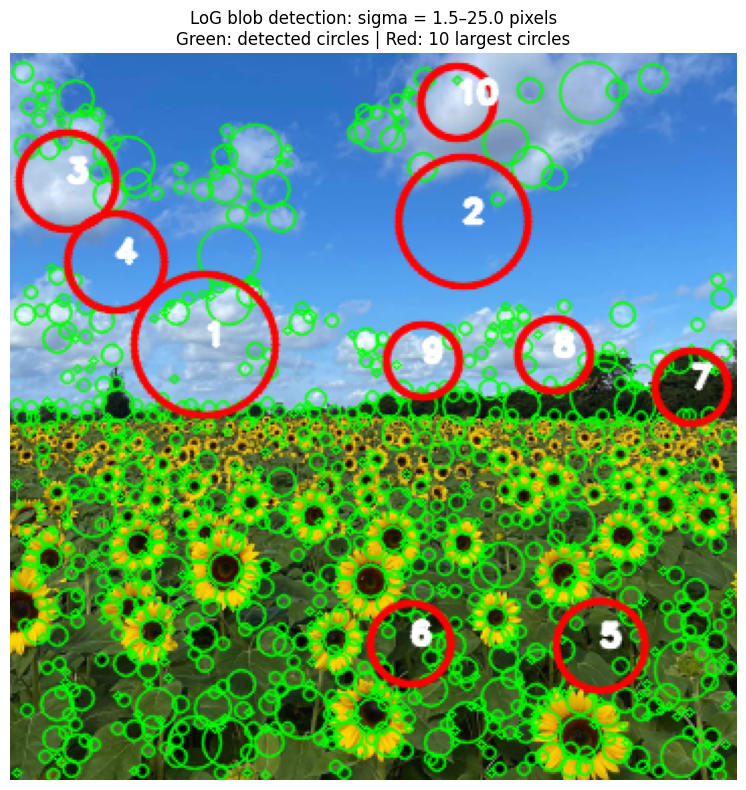

In [9]:
largest = sorted(blobs, key=lambda blob: blob[3], reverse=True)[:10]

print(f"Detection sigma range: {sigma_min:.2f}–{sigma_max:.2f} pixels")
print(f"Number of detection scales: {number_of_scales}")
print(f"Detected circles: {len(blobs)}")
print("\nLargest circles, measured in the reduced image:")
print(f"{'Rank':>4} {'x':>8} {'y':>8} {'sigma':>9} {'radius':>9}")

for rank, (x, y, sigma, radius, response) in enumerate(largest, 1):
    print(
        f"{rank:4d} {x:8.1f} {y:8.1f} "
        f"{sigma:9.3f} {radius:9.3f}"
    )

output = im.copy()

for x, y, sigma, radius, response in blobs:
    cv.circle(
        output,
        (round(x), round(y)),
        round(radius),
        (0, 255, 0),
        1,
        cv.LINE_AA
    )

for rank, (x, y, sigma, radius, response) in enumerate(largest, 1):
    center = (round(x), round(y))

    cv.circle(
        output, center, round(radius),
        (0, 0, 255), 2, cv.LINE_AA
    )

    cv.putText(
        output,
        str(rank),
        center,
        cv.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 255, 255),
        2,
        cv.LINE_AA
    )

cv.imwrite("sunflower_log_circles.jpg", output)

plt.figure(figsize=(16, 8))
plt.imshow(cv.cvtColor(output, cv.COLOR_BGR2RGB))
plt.title(
    f"LoG blob detection: sigma = {sigma_min}–{sigma_max} pixels\n"
    "Green: detected circles | Red: 10 largest circles"
)
plt.axis("off")
plt.tight_layout()
plt.show()


# **Question 2**

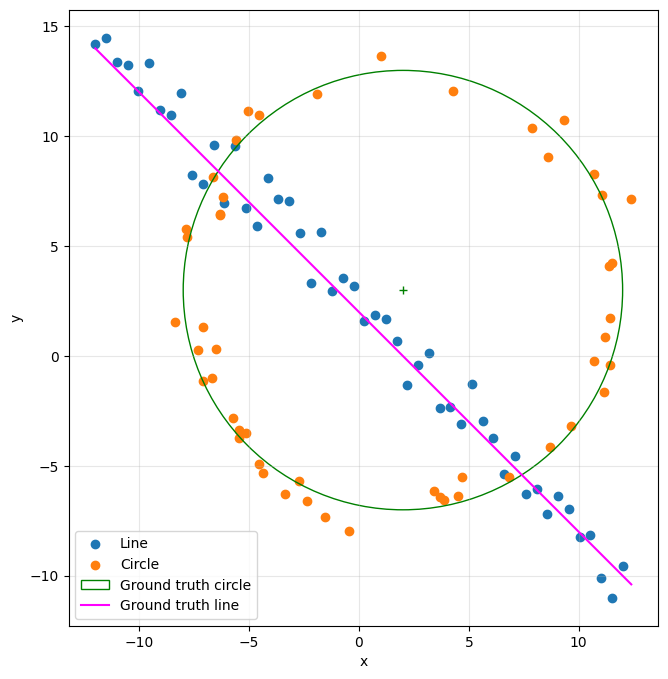

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.random.seed(0)

N = 100
half_n = N // 2

r = 10
x0_gt, y0_gt = 2, 3
s = r / 16

t = np.random.uniform(0, 2 * np.pi, half_n)
n = s * np.random.randn(half_n)

x = x0_gt + (r + n) * np.cos(t)
y = y0_gt + (r + n) * np.sin(t)

X_circ = np.column_stack((x, y))

s = 1.0
m, b_gt = -1, 2

x = np.linspace(-12, 12, half_n)
y = m * x + b_gt + s * np.random.randn(half_n)

X_line = np.column_stack((x, y))
X = np.vstack((X_circ, X_line))

fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(X_line[:, 0], X_line[:, 1], label="Line")
ax.scatter(X_circ[:, 0], X_circ[:, 1], label="Circle")

ax.add_patch(
    plt.Circle(
        (x0_gt, y0_gt), r,
        color="green", fill=False,
        label="Ground truth circle"
    )
)

ax.plot(x0_gt, y0_gt, "+", color="green")

x_plot = np.array([X[:, 0].min(), X[:, 0].max()])
ax.plot(x_plot, m * x_plot + b_gt, color="magenta",
        label="Ground truth line")

ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
ax.grid(alpha=0.3)
plt.show()